## 1. Kaggle token and dataset

In [1]:
import os
# Paste a NEW Kaggle token here. Remove it again before uploading this notebook to GitHub.
os.environ["KAGGLE_API_TOKEN"] = ""
!pip install -q --upgrade kaggle

In [2]:
!kaggle datasets download -d meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
!unzip -q gtsrb-german-traffic-sign.zip -d gtsrb
import tensorflow as tf
print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

Dataset URL: https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
License(s): CC0-1.0
100% 612M/612M [00:16<00:00, 39.1MB/s]

TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load GTSRB (known signs)

In [3]:
import numpy as np, pandas as pd
from PIL import Image

def load_images(paths):
    return np.array([np.array(Image.open(os.path.join("gtsrb", p)).convert("RGB").resize((32, 32)))
                     for p in paths], dtype="uint8")

train_df = pd.read_csv("gtsrb/Train.csv"); test_df = pd.read_csv("gtsrb/Test.csv")
X_known, y_known = load_images(train_df["Path"]), train_df["ClassId"].values
X_test, y_test = load_images(test_df["Path"]), test_df["ClassId"].values
print(X_known.shape, X_test.shape)

(39209, 32, 32, 3) (12630, 32, 32, 3)


## 3. Build the "Not a traffic sign" examples

In [4]:
import random
import numpy as np
from PIL import Image, ImageDraw, ImageFilter, ImageFont, ImageEnhance
from matplotlib import font_manager

S = 128
FONT_PATH = font_manager.findfont(font_manager.FontProperties(family="DejaVu Sans", weight="bold"))
LETTERS = "ABCDEFGHKLMNPRSTUVXYZ"

# (border, fill, symbol)  -- red fill is skipped on purpose (it looks like Stop / No entry)
STYLES = [
    ((200, 16, 46), (255, 255, 255), (10, 10, 10)),
    ((200, 16, 46), (255, 255, 255), (10, 10, 10)),
    ((200, 16, 46), (255, 255, 255), (10, 10, 10)),
    ((10, 10, 10), (255, 205, 0), (10, 10, 10)),
    ((255, 255, 255), (0, 70, 160), (255, 255, 255)),
    ((255, 255, 255), (0, 120, 60), (255, 255, 255)),
    ((10, 10, 10), (255, 140, 0), (10, 10, 10)),
    ((10, 10, 10), (255, 255, 255), (10, 10, 10)),
]
POLY = {
    "tri": [(64, 8), (120, 112), (8, 112)],
    "hex": [(34, 10), (94, 10), (122, 64), (94, 118), (34, 118), (6, 64)],
    "square": [(10, 10), (118, 10), (118, 118), (10, 118)],
}

def scale_poly(pts, k):
    cx = sum(p[0] for p in pts) / len(pts); cy = sum(p[1] for p in pts) / len(pts)
    return [(cx + (x - cx) * k, cy + (y - cy) * k) for x, y in pts]

def draw_shape(d, shape, color, k=1.0):
    if shape == "circle":
        r = 56 * k; d.ellipse((64 - r, 64 - r, 64 + r, 64 + r), fill=color)
    elif shape == "round":
        h = 54 * k; d.rounded_rectangle((64 - h, 64 - h, 64 + h, 64 + h), radius=20 * k, fill=color)
    else:
        d.polygon(scale_poly(POLY[shape], k), fill=color)

def background():
    base = np.array([random.randint(40, 200) for _ in range(3)], dtype=float)
    grad = np.linspace(-30, 30, S)[:, None, None] * random.choice([0, 1])
    img = np.clip(base + np.random.normal(0, 25, (S, S, 3)) + grad, 0, 255).astype("uint8")
    return Image.fromarray(img).filter(ImageFilter.GaussianBlur(random.uniform(2, 8)))

def pt(cx, cy, r):
    a = random.uniform(0, 6.283); rr = r * random.uniform(0.2, 1.0)
    return (cx + rr * np.cos(a), cy + rr * np.sin(a))

def draw_symbol(d, shape, col, allow_digits):
    cx, cy, r = (64, 86, 22) if shape == "tri" else (64, 64, 30)
    kind = random.choice(["text", "blobs", "wedge", "bars", "zigzag", "rings", "dots"])
    if kind == "text":
        if shape == "tri":
            s = random.choice([f"{random.randint(2, 18)}%", random.choice(LETTERS) + random.choice(LETTERS)])
        elif allow_digits and random.random() < 0.5:
            s = str(random.randint(10, 99))
        else:
            s = "".join(random.choice(LETTERS) for _ in range(random.randint(1, 2)))
        size = 56
        while size > 14:
            font = ImageFont.truetype(FONT_PATH, size)
            x0, y0, x1, y1 = d.textbbox((0, 0), s, font=font)
            if (x1 - x0) <= 2 * r and (y1 - y0) <= 1.6 * r: break
            size -= 3
        d.text((cx - (x0 + x1) / 2, cy - (y0 + y1) / 2), s, font=font, fill=col)
    elif kind == "blobs":
        for _ in range(random.randint(2, 4)):
            t = random.choice(["e", "r", "p"])
            if t == "e":
                x, y = pt(cx, cy, r * .6); w = random.uniform(5, r * .8)
                d.ellipse((x - w, y - w * random.uniform(.5, 1.3), x + w, y + w), fill=col)
            elif t == "r":
                x, y = pt(cx, cy, r * .6); w, h = random.uniform(4, r * .9), random.uniform(4, r * .9)
                d.rectangle((x - w, y - h, x + w, y + h), fill=col)
            else:
                d.polygon([pt(cx, cy, r) for _ in range(random.randint(3, 5))], fill=col)
    elif kind == "wedge":
        pts = [(cx - r, cy + r * .7), (cx + r, cy + r * .7), (cx + r, cy - r * .6)]
        if random.random() < .5: pts = [(2 * cx - x, y) for x, y in pts]
        d.polygon(pts, fill=col)
        if random.random() < .5: d.ellipse((cx - r * .5, cy - r * .9, cx - r * .1, cy - r * .5), fill=col)
    elif kind == "bars":
        n = random.randint(3, 5); vertical = random.random() < .5; step = 2 * r / n
        for i in range(n):
            a = -r + i * step
            box = (cx + a, cy - r, cx + a + step * .55, cy + r) if vertical else (cx - r, cy + a, cx + r, cy + a + step * .55)
            d.rectangle(box, fill=col)
    elif kind == "zigzag":
        n = random.randint(3, 5)
        d.line([(cx - r + i * 2 * r / n, cy + (r * .6 if i % 2 else -r * .6)) for i in range(n + 1)], fill=col, width=random.randint(5, 9))
    elif kind == "rings":
        for k in (1.0, .6, .25):
            d.ellipse((cx - r * k, cy - r * k, cx + r * k, cy + r * k), outline=col, width=5)
    else:
        for i in (-1, 0, 1):
            for j in (-1, 0, 1):
                d.ellipse((cx + i * r * .7 - 5, cy + j * r * .7 - 5, cx + i * r * .7 + 5, cy + j * r * .7 + 5), fill=col)

def make_unknown_sign():
    bg = background(); d = ImageDraw.Draw(bg)
    border, fill, sym = random.choice(STYLES)
    shape = random.choice(["tri", "tri", "circle", "circle", "round", "hex", "square"])
    draw_shape(d, shape, border, 1.0)
    draw_shape(d, shape, fill, random.uniform(0.72, 0.86))
    red_circle = shape == "circle" and border == (200, 16, 46)
    draw_symbol(d, shape, sym, allow_digits=not red_circle)
    m = random.randint(0, 8)
    img = bg.crop((m, m, S - m, S - m))
    img = ImageEnhance.Brightness(img).enhance(random.uniform(0.55, 1.3))
    img = ImageEnhance.Contrast(img).enhance(random.uniform(0.6, 1.2))
    img = img.filter(ImageFilter.GaussianBlur(random.uniform(0.5, 3.0))).resize((32, 32), Image.LANCZOS)
    arr = np.array(img, dtype=float) + np.random.normal(0, random.uniform(0, 6), (32, 32, 3))
    return np.clip(arr, 0, 255).astype("uint8")

def synthetic_signs(n, seed):
    random.seed(seed); np.random.seed(seed)
    return np.stack([make_unknown_sign() for _ in range(n)])

In [5]:
from tensorflow import keras
from PIL import ImageOps

UNKNOWN = 43
rng = np.random.default_rng(42)

# (a) generated sign-like images that are not GTSRB signs
X_synth = synthetic_signs(4000, seed=1)

# (b) everyday photos
(c_train, _), (c_test, _) = keras.datasets.cifar100.load_data()
X_cifar = c_train[rng.permutation(len(c_train))[:2000]]

X_neg = np.concatenate([X_synth, X_cifar])
print("Negatives:", X_neg.shape)

# (c) "clean graphic" copies of known signs, so the model does not learn that clean images = not a sign
def clean_style(a):
    im = Image.fromarray(a).resize((128, 128), Image.BICUBIC)
    im = ImageOps.autocontrast(im, cutoff=3).filter(ImageFilter.MedianFilter(5))
    im = ImageEnhance.Color(im).enhance(1.4)
    return np.array(im.resize((32, 32), Image.LANCZOS))

idx = rng.permutation(len(X_known))[:8000]
X_clean = np.stack([clean_style(X_known[i]) for i in idx]); y_clean = y_known[idx]

X_all = np.concatenate([X_known, X_clean, X_neg])
y_all = np.concatenate([y_known, y_clean, np.full(len(X_neg), UNKNOWN)])
print("Total training pool:", X_all.shape, "| classes:", len(np.unique(y_all)))

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 1459s 9us/step
Negatives: (6000, 32, 32, 3)
Total training pool: (53209, 32, 32, 3) | classes: 44


## 4. Model and training

In [6]:
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers

X_train, X_val, y_train, y_val = train_test_split(X_all, y_all, test_size=0.15, random_state=42, stratify=y_all)

model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.RandomContrast(0.2),
    layers.Rescaling(1./255),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(44, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=callbacks)

Epoch 1/30
707/707 ━━━━━━━━━━━━━━━━━━━━ 22s 17ms/step - accuracy: 0.3338 - loss: 2.3488 - val_accuracy: 0.5140 - val_loss: 1.8702 - learning_rate: 0.0010
Epoch 2/30
707/707 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.5856 - loss: 1.2399 - val_accuracy: 0.8256 - val_loss: 0.5362 - learning_rate: 0.0010
Epoch 3/30
707/707 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.7748 - loss: 0.6789 - val_accuracy: 0.9551 - val_loss: 0.1513 - learning_rate: 0.0010
Epoch 4/30
707/707 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.8725 - loss: 0.4012 - val_accuracy: 0.9782 - val_loss: 0.0715 - learning_rate: 0.0010
Epoch 5/30
707/707 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.9137 - loss: 0.2812 - val_accuracy: 0.9847 - val_loss: 0.0577 - learning_rate: 0.0010
Epoch 6/30
707/707 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.9315 - loss: 0.2236 - val_accuracy: 0.9766 - val_loss: 0.0878 - learning_rate: 0.0010
Epoch 7/30
707/707 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9434 - l

## 5. Evaluation (send these numbers back to Claude)

In [7]:
from sklearn.metrics import precision_recall_fscore_support

pred = model.predict(X_test, batch_size=256, verbose=0).argmax(axis=1)
print(f"Official test accuracy (43 real signs)        : {(pred == y_test).mean():.4f}")
print(f"Real signs wrongly rejected as 'not a sign'    : {(pred == UNKNOWN).mean():.4f}")
p, r, f, _ = precision_recall_fscore_support(y_test, pred, labels=list(range(43)), average="macro", zero_division=0)
print(f"Macro precision / recall / F1 (43 signs)       : {p:.4f} / {r:.4f} / {f:.4f}")

clean_pred = model.predict(np.stack([clean_style(a) for a in X_test[:3000]]), verbose=0).argmax(axis=1)
print(f"Clean-graphic style real signs recognised      : {(clean_pred == y_test[:3000]).mean():.4f}")

cifar_pred = model.predict(c_test[:2000], verbose=0).argmax(axis=1)
print(f"Unseen everyday photos rejected                : {(cifar_pred == UNKNOWN).mean():.4f}")
synth_pred = model.predict(synthetic_signs(1000, seed=999), verbose=0).argmax(axis=1)
print(f"Unseen generated unknown signs rejected        : {(synth_pred == UNKNOWN).mean():.4f}  (optimistic, same generator)")

Official test accuracy (43 real signs)        : 0.9844
Real signs wrongly rejected as 'not a sign'    : 0.0035
Macro precision / recall / F1 (43 signs)       : 0.9810 / 0.9775 / 0.9782
Clean-graphic style real signs recognised      : 0.9847
Unseen everyday photos rejected                : 0.9880
Unseen generated unknown signs rejected        : 1.0000  (optimistic, same generator)


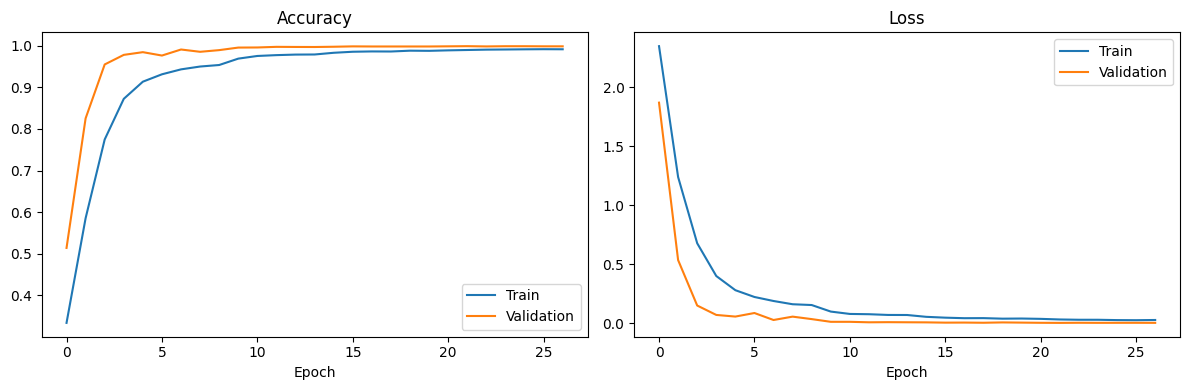

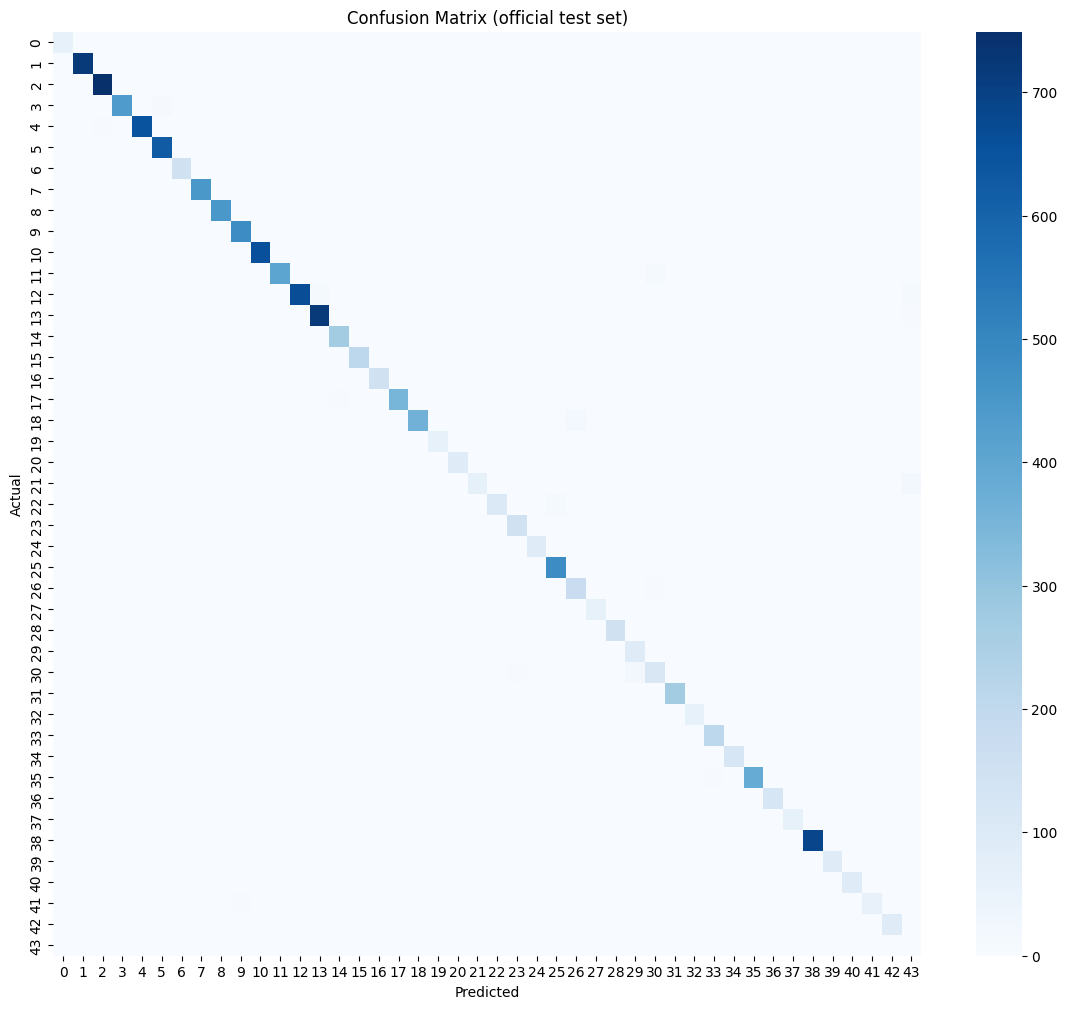

In [8]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="Train"); ax[0].plot(history.history["val_accuracy"], label="Validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="Train"); ax[1].plot(history.history["val_loss"], label="Validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

cm = confusion_matrix(y_test, pred, labels=list(range(44)))
plt.figure(figsize=(14, 12)); sns.heatmap(cm, cmap="Blues")
plt.title("Confusion Matrix (official test set)"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.savefig("confusion_matrix.png", dpi=150); plt.show()

## 6. Save and download (4 files)

In [9]:
class_names = {
    0: "Speed limit (20km/h)", 1: "Speed limit (30km/h)", 2: "Speed limit (50km/h)",
    3: "Speed limit (60km/h)", 4: "Speed limit (70km/h)", 5: "Speed limit (80km/h)",
    6: "End of speed limit (80km/h)", 7: "Speed limit (100km/h)", 8: "Speed limit (120km/h)",
    9: "No passing", 10: "No passing for vehicles over 3.5 tons",
    11: "Right-of-way at next intersection", 12: "Priority road", 13: "Yield",
    14: "Stop", 15: "No vehicles", 16: "Vehicles over 3.5 tons prohibited",
    17: "No entry", 18: "General caution", 19: "Dangerous curve to the left",
    20: "Dangerous curve to the right", 21: "Double curve", 22: "Bumpy road",
    23: "Slippery road", 24: "Road narrows on the right", 25: "Road work",
    26: "Traffic signals", 27: "Pedestrians", 28: "Children crossing",
    29: "Bicycles crossing", 30: "Beware of ice/snow", 31: "Wild animals crossing",
    32: "End of all speed and passing limits", 33: "Turn right ahead",
    34: "Turn left ahead", 35: "Ahead only", 36: "Go straight or right",
    37: "Go straight or left", 38: "Keep right", 39: "Keep left",
    40: "Roundabout mandatory", 41: "End of no passing",
    42: "End of no passing by vehicles over 3.5 tons",
    43: "Not a traffic sign",
}

import json
from google.colab import files

with open("class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)
model.save("signsense_model.keras")

for name in ["signsense_model.keras", "class_names.json", "training_curves.png", "confusion_matrix.png"]:
    files.download(name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>